# Combine ArcticDEM tiles for the Juneau Icefield

## Workflow

1. Discover and check all six raw ArcticDEM tiles.
2. Define the regional mosaic extent from their combined footprints and the detailed radar extent from the observations.
3. Mosaic at the native **2 m / EPSG:3413** grid, then reproject each output once to **WGS 84 / UTM Zone 8N**.
4. Check missing cells and elevation coverage at every radar location.
5. Preview the terrain and radar tracks.

**Kernel:** JIF snow modeling (`jif_snow_modeling`).

**Output folder:** `/hdd/snow_hydrology/DEMs/ArcticDEM_edits/icefield_domain/jif_mosaic/`.

- **Regional extent:** the combined extent of the downloaded tiles; no separate geographic domain rectangle is imposed.
- **Radar extent:** the radar footprint plus a 5 km buffer.
- **Nodata:** source voids remain missing; no filling is performed.
- **Detail:** native and virtual products retain a 2 m grid; the regional GeoTIFF is averaged to 20 m.

For an overview with hillshade and basemap context, open **`01_open_jif_dem_mosaic.ipynb`** after this notebook.

In [1]:
from pathlib import Path
import json, math, hashlib, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon as PolygonPatch
from matplotlib.colors import ListedColormap
from IPython.display import display
import rasterio
from rasterio.warp import transform_bounds
from rasterio.features import rasterize
from rasterio.windows import Window
from shapely.geometry import box, mapping
from shapely.ops import transform as transform_geometry, unary_union
from pyproj import Transformer
from osgeo import gdal

gdal.UseExceptions()
gdal.SetCacheMax(256 * 1024**2)
RAW_DIR = Path('/hdd/snow_hydrology/DEMs/ArcticDEM')
OUTPUT_DIR = Path('/hdd/snow_hydrology/DEMs/ArcticDEM_edits/icefield_domain/jif_mosaic')
RADAR_CSV = Path('/hdd/snow_hydrology/JIF_radar/ml_swe_2021.csv')
TARGET_CRS = 'EPSG:32608'
# The radar documentation gives UTM Zone 8N, but not its datum.
RADAR_CRS = 'EPSG:32608'  # Provisional WGS 84 assumption, as in radar exploration.
DOMAIN_RES_M = 20
RADAR_RES_M = 2
RADAR_BUFFER_M = 5000
BUILD_RADAR_TIF = True
OVERWRITE = False  # Existing outputs are reused only when provenance matches.
NODATA = -9999.0
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print('Python:', sys.executable)
print('GDAL:', gdal.VersionInfo('--version'))
print('Outputs:', OUTPUT_DIR)

Python: /home/cassie/programs/miniforge3/envs/jif_snow_modeling/bin/python
GDAL: GDAL 3.10.3, released 2025/04/01
Outputs: /hdd/snow_hydrology/DEMs/ArcticDEM_edits/icefield_domain/jif_mosaic


## 1. Inventory raw tiles and check metadata

- Require one band, a common CRS, common 2 m resolution, and the declared -9999 sentinel.
- Record file size and modification time to detect changed inputs when reusing outputs.
- **Preview missing percentages are approximate:** they use a nearest-neighbour 600 × 600 sample, not an exhaustive native-resolution count.
- Build densified tile footprints in UTM for coverage checks; a footprint describes available tile extent, not validity of every pixel.

In [2]:
tile_paths = sorted(RAW_DIR.glob('*/*_dem.tif'))
if not tile_paths:
    raise FileNotFoundError(f'No raw DEM tiles found under {RAW_DIR}')
records, footprints, signatures = [], [], []
source_crs, source_res = None, None
for path in tile_paths:
    with rasterio.open(path) as src:
        if source_crs is None:
            source_crs, source_res = src.crs, src.res
        if src.crs != source_crs or src.res != source_res or src.count != 1:
            raise ValueError(f'Inconsistent tile metadata: {path}')
        if src.nodata != NODATA:
            raise ValueError(f'Inspect unexpected nodata before continuing: {path}: {src.nodata}')
        preview = src.read(1, out_shape=(600, 600), masked=True)
        invalid = np.ma.getmaskarray(preview) | ~np.isfinite(preview.data)
        to_utm = Transformer.from_crs(src.crs, TARGET_CRS, always_xy=True)
        footprint = transform_geometry(to_utm.transform, box(*src.bounds).segmentize(1000))
        footprints.append(footprint)
        stat = path.stat()
        signatures.append({'path': str(path), 'size_bytes': stat.st_size, 'mtime_ns': stat.st_mtime_ns})
        records.append({'tile': path.parent.name, 'path': str(path), 'crs': str(src.crs),
                        'resolution_m': src.res[0], 'width': src.width, 'height': src.height,
                        'nodata': src.nodata, 'preview_missing_percent': 100 * invalid.mean()})
if source_res != (2.0, 2.0):
    raise ValueError(f'Expected native 2 m inputs, found {source_res}')
inventory = pd.DataFrame(records)
display(inventory)
inventory.to_csv(OUTPUT_DIR / 'tile_inventory.csv', index=False)
print(f'{len(tile_paths)} tiles discovered; native CRS: {source_crs}')

6 tiles discovered; native CRS: EPSG:3413


,tile,path,crs,resolution_m,width,height,nodata,preview_missing_percent
0,40_05_1_2,/hdd/snow_hydrology/DEMs/ArcticDEM/40_05_1_2/4...,EPSG:3413,2.0,25100,25100,-9999.0,0.050833
1,40_05_2_2,/hdd/snow_hydrology/DEMs/ArcticDEM/40_05_2_2/4...,EPSG:3413,2.0,25100,25100,-9999.0,0.017778
2,40_06_1_1,/hdd/snow_hydrology/DEMs/ArcticDEM/40_06_1_1/4...,EPSG:3413,2.0,25100,25100,-9999.0,0.141667
3,40_06_1_2,/hdd/snow_hydrology/DEMs/ArcticDEM/40_06_1_2/4...,EPSG:3413,2.0,25100,25100,-9999.0,0.011389
4,40_06_2_1,/hdd/snow_hydrology/DEMs/ArcticDEM/40_06_2_1/4...,EPSG:3413,2.0,25100,25100,-9999.0,0.020556
5,40_06_2_2,/hdd/snow_hydrology/DEMs/ArcticDEM/40_06_2_2/4...,EPSG:3413,2.0,25100,25100,-9999.0,0.000000


## 2. Tile-derived extent and radar footprint

- Combine the densified UTM tile footprints and use their outer bounds for the regional output grid.
- Plot actual tile outlines and every finite radar coordinate.
- A rectangular raster grid can include small corners outside the tile footprints; these stay nodata.
- Use the radar footprint plus a **5 km buffer** for the detailed 2 m product.

> **Radar coordinates:** the source documentation specifies UTM Zone 8N without a datum. The overlay provisionally assumes WGS 84; confirm it before quantitative spatial matching.

Regional bounds from downloaded tiles: (499904.13176204613, 6433978.304836114, 595965.5088519293, 6577726.722376159)


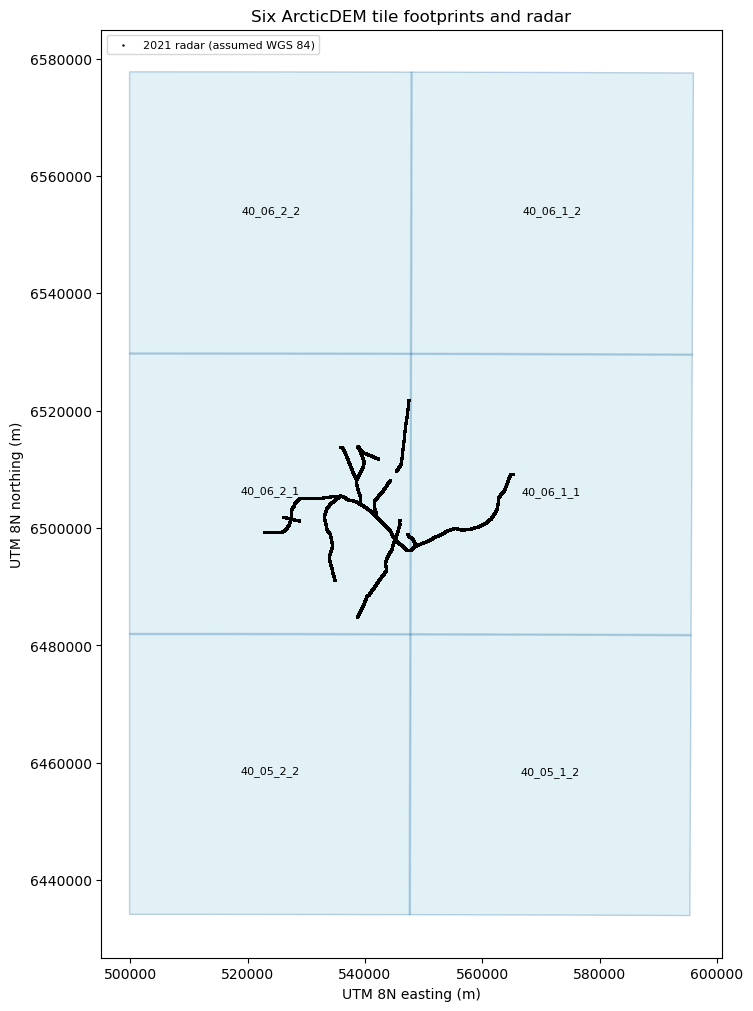

In [3]:
coverage = unary_union(footprints)
domain_bounds = coverage.bounds
radar = pd.read_csv(RADAR_CSV, encoding='utf-8-sig')
coordinate_ok = np.isfinite(radar[['east', 'north']]).all(axis=1)
radar_xy = radar.loc[coordinate_ok, ['east', 'north']].to_numpy()
if len(radar_xy) == 0:
    raise ValueError('No finite radar coordinates.')
radar_transform = Transformer.from_crs(RADAR_CRS, TARGET_CRS, always_xy=True)
radar_x, radar_y = radar_transform.transform(radar_xy[:, 0], radar_xy[:, 1])
radar_bounds = (float(np.min(radar_x) - RADAR_BUFFER_M), float(np.min(radar_y) - RADAR_BUFFER_M),
                float(np.max(radar_x) + RADAR_BUFFER_M), float(np.max(radar_y) + RADAR_BUFFER_M))
print('Regional bounds from downloaded tiles:', domain_bounds)
fig, ax = plt.subplots(figsize=(10, 10), constrained_layout=True)
for record, footprint in zip(records, footprints):
    ax.add_patch(PolygonPatch(np.asarray(footprint.exterior.coords), facecolor='lightblue',
                              edgecolor='steelblue', alpha=0.35))
    ax.text(footprint.centroid.x, footprint.centroid.y, record['tile'], ha='center', fontsize=8)
ax.scatter(radar_x, radar_y, s=0.5, color='black', rasterized=True, label='2021 radar (assumed WGS 84)')
ax.set(xlabel='UTM 8N easting (m)', ylabel='UTM 8N northing (m)', title='Six ArcticDEM tile footprints and radar')
ax.set_aspect('equal'); ax.autoscale_view(); ax.legend(loc='upper left', fontsize=8)
ax.ticklabel_format(style='plain', useOffset=False)
fig.savefig(OUTPUT_DIR / 'jif_tile_coverage.png', dpi=160)
plt.show()

## 3. Build the mosaics and UTM products

### Processing settings

- **Mosaic first:** the native VRT references the raw tiles without copying all elevation pixels.
- **Nodata:** -9999 is excluded from overlaps and resampling. Later tiles in the sorted list take priority where both have valid values.
- **Single reprojection per product:** use average resampling for 20 m and bilinear resampling for 2 m outputs.
- **Bounded memory:** use tiled, compressed GeoTIFFs and GDAL's chunked warper.
- **Source overviews:** disabled during warping so the requested resampling operates on the source grid.

| Product | Purpose |
| --- | --- |
| `jif_arcticdem_native_2m.vrt` | All raw tiles in their native grid |
| `jif_tiles_utm8n_2m.vrt` | Combined tile extent in UTM, evaluated on demand |
| `jif_tiles_utm8n_20m.tif` | Regional terrain covering the six tiles |
| `jif_radar_utm8n_2m.tif` | Radar tracks plus 5 km buffer |

**VRTs require the original source files.** No vertical datum conversion or void filling is applied.

Products are reused only when their recorded inputs and relevant settings agree. New files are written to temporary paths and renamed after successful completion. Keep `OVERWRITE = False` unless deliberately rebuilding.

References: [GDAL mosaics](https://gdal.org/en/stable/programs/gdalbuildvrt.html), [GDAL warping and nodata](https://gdal.org/en/stable/programs/gdalwarp.html).

In [4]:
settings = {'sources': signatures, 'source_crs': str(source_crs), 'nodata': NODATA,
            'target_crs': TARGET_CRS, 'domain_bounds': list(domain_bounds),
            'radar_bounds': list(radar_bounds), 'radar_crs_assumption': RADAR_CRS,
            'domain_resolution_m': DOMAIN_RES_M, 'radar_resolution_m': RADAR_RES_M,
            'build_radar_tif': BUILD_RADAR_TIF, 'gdal': gdal.VersionInfo(),
            'domain_resampling': 'average', 'radar_resampling': 'bilinear',
            'source_overviews': 'NONE', 'workflow_version': 2}
manifest_path = OUTPUT_DIR / 'tile_extent_processing_manifest.json'
previous = json.loads(manifest_path.read_text()) if manifest_path.exists() else {}
legacy_path = OUTPUT_DIR / 'processing_manifest.json'
legacy = json.loads(legacy_path.read_text()).get('settings', {}) if legacy_path.exists() else {}
product_records = previous.get('products', {})
native_vrt = OUTPUT_DIR / 'jif_arcticdem_native_2m.vrt'
domain_vrt = OUTPUT_DIR / 'jif_tiles_utm8n_2m.vrt'
domain_tif = OUTPUT_DIR / f'jif_tiles_utm8n_{DOMAIN_RES_M:g}m.tif'
radar_tif = OUTPUT_DIR / f'jif_radar_utm8n_{RADAR_RES_M:g}m.tif'

def aligned(bounds, resolution):
    left, bottom, right, top = bounds
    return (math.floor(left / resolution) * resolution, math.floor(bottom / resolution) * resolution,
            math.ceil(right / resolution) * resolution, math.ceil(top / resolution) * resolution)

def save_manifest():
    manifest_path.write_text(json.dumps({'settings': settings, 'products': product_records}, indent=2))

def reuse_product(path, spec, legacy_keys=()):
    if not path.exists() or OVERWRITE:
        return False
    recorded = product_records.get(path.name, {}).get('settings')
    legacy_matches = bool(legacy_keys) and all(legacy.get(k) == settings.get(k) for k in legacy_keys)
    if recorded != spec and not (recorded is None and legacy_matches):
        raise RuntimeError(f'Existing {path.name} lacks matching provenance; inspect before setting OVERWRITE=True.')
    product_records[path.name] = {'path': str(path), 'settings': spec}
    save_manifest()
    print('Reusing verified product:', path.name, flush=True)
    return True

native_spec = {k: settings[k] for k in ['sources', 'source_crs', 'nodata', 'gdal']}
if not reuse_product(native_vrt, native_spec, tuple(native_spec)):
    temp = native_vrt.with_name(native_vrt.stem + '.partial.vrt')
    dataset = gdal.BuildVRT(str(temp), [str(p) for p in tile_paths], options=gdal.BuildVRTOptions(
        strict=True, resolution='highest', srcNodata=NODATA, VRTNodata=NODATA))
    if dataset is None:
        raise RuntimeError('VRT creation failed.')
    dataset.FlushCache(); dataset = None; temp.replace(native_vrt)
    product_records[native_vrt.name] = {'path': str(native_vrt), 'settings': native_spec}
    save_manifest()

def warp_product(path, bounds, resolution, algorithm, virtual=False, radar_product=False):
    spec = dict(native_spec, target_crs=TARGET_CRS, bounds=list(aligned(bounds, resolution)),
                resolution_m=resolution, algorithm=algorithm, virtual=virtual, source_overviews='NONE')
    if radar_product:
        spec['radar_crs_assumption'] = RADAR_CRS
    legacy_keys = ('sources', 'source_crs', 'nodata', 'gdal', 'target_crs', 'radar_bounds',
                   'radar_resolution_m', 'radar_resampling', 'radar_crs_assumption', 'source_overviews') if radar_product else ()
    if reuse_product(path, spec, legacy_keys):
        return
    temp = path.with_name(path.stem + '.partial' + path.suffix)
    options = dict(format='VRT' if virtual else 'GTiff', dstSRS=TARGET_CRS,
                   outputBounds=aligned(bounds, resolution), xRes=resolution, yRes=resolution,
                   srcNodata=NODATA, dstNodata=NODATA, resampleAlg=algorithm,
                   outputType=gdal.GDT_Float32, overviewLevel='NONE',
                   warpMemoryLimit=256, multithread=True, warpOptions=['NUM_THREADS=2'])
    if not virtual:
        options['creationOptions'] = ['TILED=YES', 'COMPRESS=DEFLATE', 'PREDICTOR=3',
                                       'BIGTIFF=IF_SAFER', 'NUM_THREADS=2']
    print('Building:', path.name, flush=True)
    dataset = gdal.Warp(str(temp), str(native_vrt), options=gdal.WarpOptions(**options))
    if dataset is None:
        raise RuntimeError(f'Warp failed: {path}')
    dataset.FlushCache(); dataset = None; temp.replace(path)
    product_records[path.name] = {'path': str(path), 'settings': spec}
    save_manifest()

warp_product(domain_vrt, domain_bounds, 2, 'bilinear', virtual=True)
warp_product(domain_tif, domain_bounds, DOMAIN_RES_M, 'average')
if BUILD_RADAR_TIF:
    warp_product(radar_tif, radar_bounds, RADAR_RES_M, 'bilinear', radar_product=True)
print('Tile-extent mosaic products are ready.')

Reusing verified product: jif_arcticdem_native_2m.vrt
Building: jif_tiles_utm8n_2m.vrt
Building: jif_tiles_utm8n_20m.tif
Reusing verified product: jif_radar_utm8n_2m.tif
Tile-extent mosaic products are ready.


## 4. Exact output-grid audits and radar-point checks

- Count invalid values **block by block** using both the raster mask and non-finite checks.
- Separate missing cells inside downloaded tile footprints from cells outside all footprints. Footprint classification uses output-cell centres; edge pixels may differ from resampling support.
- Compare raw native 2 m samples and new products at every finite radar coordinate. This is a coverage check, not a vertical-accuracy assessment.
- Sample nearest cells in blocks rather than reading the entire full-resolution DEM.
- Genuine remaining voids stay nodata; small gaps may need a separately justified repair later.

In [5]:
def audit_raster(path):
    counts = dict(pixels=0, valid=0, invalid_inside_tile_extent=0, invalid_outside_tile_extent=0,
                  valid_below_minus1000=0)
    minimum, maximum = np.inf, -np.inf
    with rasterio.open(path) as src:
        shapes = [(mapping(p), 1) for p in footprints]
        for _, window in src.block_windows(1):
            data = src.read(1, window=window, masked=True)
            invalid = np.ma.getmaskarray(data) | ~np.isfinite(data.data)
            inside = rasterize(shapes, out_shape=data.shape, transform=src.window_transform(window),
                               fill=0, dtype='uint8').astype(bool)
            good = ~invalid
            counts['pixels'] += data.size
            counts['valid'] += int(good.sum())
            counts['invalid_inside_tile_extent'] += int((invalid & inside).sum())
            counts['invalid_outside_tile_extent'] += int((invalid & ~inside).sum())
            counts['valid_below_minus1000'] += int((good & (data.data < -1000)).sum())
            if good.any():
                minimum = min(minimum, float(data.data[good].min()))
                maximum = max(maximum, float(data.data[good].max()))
        counts.update(file=path.name, resolution_m=src.res[0], min_valid_m=minimum,
                      max_valid_m=maximum, missing_percent=100 * (counts['pixels'] - counts['valid']) / counts['pixels'])
    return counts

audit_paths = [domain_tif] + ([radar_tif] if BUILD_RADAR_TIF else [])
audit = pd.DataFrame([audit_raster(p) for p in audit_paths])
audit.to_csv(OUTPUT_DIR / 'tile_extent_dem_quality_summary.csv', index=False)
display(audit)

def sample_in_blocks(path, x, y, coordinate_crs):
    values = np.full(len(x), np.nan)
    in_bounds = np.zeros(len(x), dtype=bool)
    with rasterio.open(path) as src:
        transformer = Transformer.from_crs(coordinate_crs, src.crs, always_xy=True)
        sx, sy = transformer.transform(x, y)
        rows, cols = rasterio.transform.rowcol(src.transform, sx, sy)
        rows, cols = np.asarray(rows), np.asarray(cols)
        in_bounds = (rows >= 0) & (rows < src.height) & (cols >= 0) & (cols < src.width)
        ids = np.flatnonzero(in_bounds)
        block_size = 512
        groups = pd.DataFrame({'index': ids, 'br': rows[ids] // block_size, 'bc': cols[ids] // block_size})
        for (br, bc), group in groups.groupby(['br', 'bc']):
            row0, col0 = int(br * block_size), int(bc * block_size)
            window = Window(col0, row0, min(block_size, src.width - col0), min(block_size, src.height - row0))
            data = src.read(1, window=window, masked=True)
            ii = group['index'].to_numpy()
            samples = data[rows[ii] - row0, cols[ii] - col0]
            values[ii] = samples.astype(float).filled(np.nan)
    values[~np.isfinite(values)] = np.nan
    return values, in_bounds

point_checks = pd.DataFrame({'source_csv_row_0based': radar.index[coordinate_ok],
                            'east': radar_x, 'north': radar_y})
point_summary = []
compare_paths = [('raw_native_2m', native_vrt), ('tiles_20m', domain_tif)]
if BUILD_RADAR_TIF:
    compare_paths.append(('radar_2m', radar_tif))
for label, path in compare_paths:
    values, in_bounds = sample_in_blocks(path, radar_x, radar_y, TARGET_CRS)
    point_checks[label + '_elevation_m'] = values
    point_checks[label + '_in_bounds'] = in_bounds
    point_summary.append({'product': label, 'points_checked': len(values),
                          'outside_raster': int((~in_bounds).sum()),
                          'inside_but_invalid': int((in_bounds & ~np.isfinite(values)).sum()),
                          'valid': int(np.isfinite(values).sum())})
point_checks.to_csv(OUTPUT_DIR / 'tile_extent_radar_dem_samples.csv', index=False)
point_summary = pd.DataFrame(point_summary)
point_summary.to_csv(OUTPUT_DIR / 'tile_extent_radar_coverage_summary.csv', index=False)
display(point_summary)
print('Radar rows without finite coordinates:', int((~coordinate_ok).sum()))

Radar rows without finite coordinates: 0


,pixels,valid,invalid_inside_tile_extent,invalid_outside_tile_extent,valid_below_minus1000,file,resolution_m,min_valid_m,max_valid_m,missing_percent
0,34535956,34333704,40508,161744,0,jif_tiles_utm8n_20m.tif,20.0,-35.866631,2461.634277,0.585627
1,615834335,615395189,439146,0,0,jif_radar_utm8n_2m.tif,2.0,-30.784111,2412.825195,0.071309


,product,points_checked,outside_raster,inside_but_invalid,valid
0,raw_native_2m,119218,0,0,119218
1,tiles_20m,119218,0,0,119218
2,radar_2m,119218,0,0,119218


## 5. Preview terrain and missing-data categories

- Overview images are reduced-resolution nearest-neighbour previews; they can miss very small holes. Use the exact QA tables above for counts.
- Show the full six-tile extent and the radar area, with all radar points overlaid.
- Source-extent gaps remain visible separately from gaps inside downloaded footprints.
- No hillshade or filling is used to conceal missing elevation values.

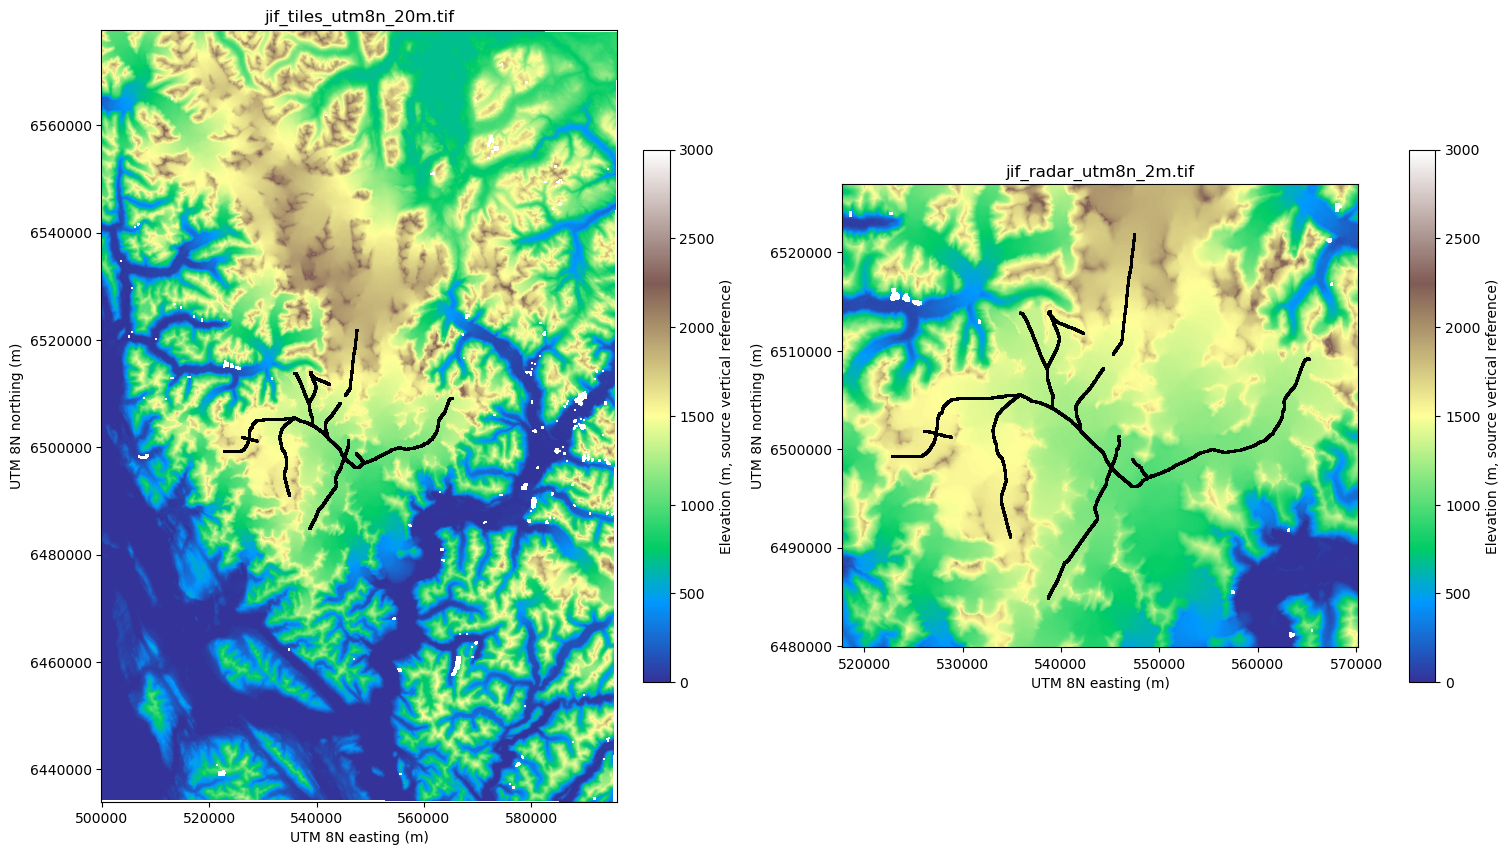

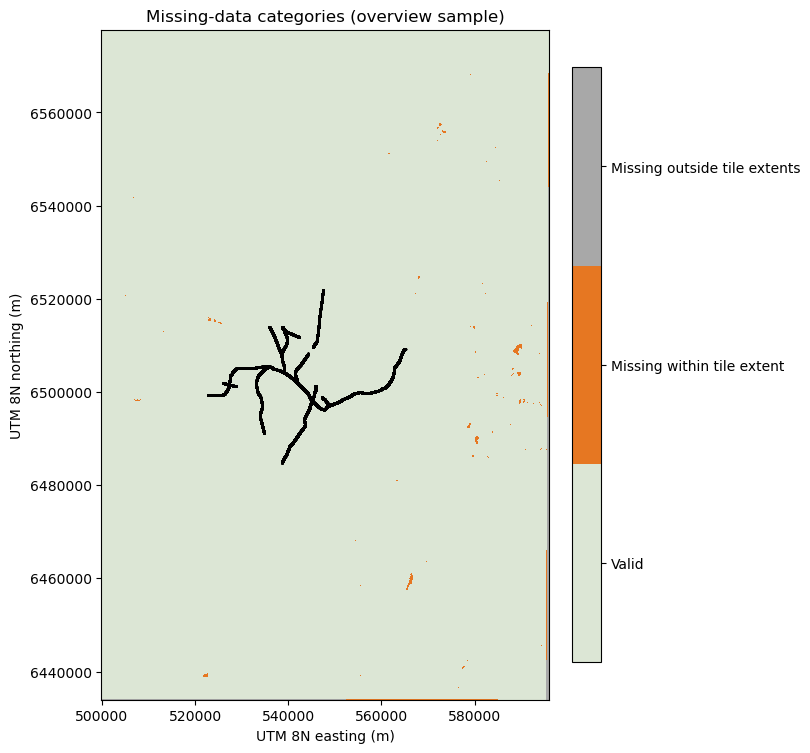

In [6]:
def preview_dem(path, max_size=1400):
    with rasterio.open(path) as src:
        factor = max(src.width, src.height) / max_size
        height, width = min(src.height, max(1, round(src.height / factor))), min(src.width, max(1, round(src.width / factor)))
        data = src.read(1, out_shape=(height, width), masked=True)
        invalid = np.ma.getmaskarray(data) | ~np.isfinite(data.data)
        data = np.ma.array(data.data, mask=invalid)
        transform = src.transform * src.transform.scale(src.width / width, src.height / height)
        inside = rasterize([(mapping(p), 1) for p in footprints], out_shape=data.shape,
                           transform=transform, fill=0, dtype='uint8').astype(bool)
        return data, inside, [src.bounds.left, src.bounds.right, src.bounds.bottom, src.bounds.top]

fig, axes = plt.subplots(1, 2, figsize=(15, 9), constrained_layout=True)
for ax, path in zip(axes, [domain_tif, radar_tif if BUILD_RADAR_TIF else domain_vrt]):
    data, inside, extent = preview_dem(path)
    im = ax.imshow(data, extent=extent, cmap='terrain', origin='upper', vmin=0, vmax=3000)
    ax.scatter(radar_x, radar_y, s=0.15, color='black', rasterized=True)
    ax.set(title=path.name, xlabel='UTM 8N easting (m)', ylabel='UTM 8N northing (m)')
    ax.ticklabel_format(style='plain', useOffset=False)
    fig.colorbar(im, ax=ax, shrink=0.6, label='Elevation (m, source vertical reference)')
fig.savefig(OUTPUT_DIR / 'jif_dem_radar_overview.png', dpi=160)
plt.show()

data, inside, extent = preview_dem(domain_tif)
missing = np.ma.getmaskarray(data)
categories = np.zeros(data.shape, dtype='uint8')
categories[missing & inside] = 1
categories[missing & ~inside] = 2
fig, ax = plt.subplots(figsize=(8, 10), constrained_layout=True)
im = ax.imshow(categories, extent=extent, origin='upper',
               cmap=ListedColormap(['#dce6d5', '#e67722', '#a8a8a8']), vmin=-0.5, vmax=2.5)
ax.scatter(radar_x, radar_y, s=0.15, color='black', rasterized=True)
ax.set(title='Missing-data categories (overview sample)', xlabel='UTM 8N easting (m)', ylabel='UTM 8N northing (m)')
ax.ticklabel_format(style='plain', useOffset=False)
bar = fig.colorbar(im, ax=ax, ticks=[0, 1, 2], shrink=0.6)
bar.ax.set_yticklabels(['Valid', 'Missing within tile extent', 'Missing outside tile extents'])
fig.savefig(OUTPUT_DIR / 'jif_dem_missing_coverage.png', dpi=160)
plt.show()

## Using the results

- **Visualization:** open `01_open_jif_dem_mosaic.ipynb` for shaded terrain, radar tracks, and basemap context.
- **Regional work:** use the 20 m tile-extent GeoTIFF.
- **Detailed work:** use the 2 m radar GeoTIFF or read windows from the virtual 2 m mosaic.
- **Coverage:** use the exact output QA tables and radar sample checks; overview images can hide tiny voids.
- **Source reference:** retain the unfilled mosaics and confirm the radar datum and source elevation reference before quantitative comparison.

All large products remain under `/hdd`. Existing products from earlier runs are left in place; the active regional filenames now start with **`jif_tiles_`**.